In [6]:
import os, tarfile, numpy as np, tensorflow as tf
from scipy.io import wavfile
from sklearn.metrics import confusion_matrix

KEYWORDS = ["go", "stop", "off", "on"]          # tes mots
CLASSES  = KEYWORDS + ["_silence_", "_unknown_"]

SIL, UNK = len(KEYWORDS), len(KEYWORDS) + 1

SR, N = 16000, 16000                    # 1 s @ 16 kHz
NFFT, HOP = 256, 160                    # fenêtre 16 ms, pas 10 ms
EPOCHS, BATCH = 25, 64
DATA = "data"
tf.keras.utils.set_random_seed(0)

In [7]:
url = "http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz"
tgz = tf.keras.utils.get_file("sc.tar.gz", url, cache_dir=".", cache_subdir=DATA)
if not os.path.isdir(f"{DATA}/_background_noise_") or not os.path.isdir(f"{DATA}/bed"):
    with tarfile.open(tgz, "r:gz") as t:
        t.extractall(DATA)

2428923189/2428923189 ━━━━━━━━━━━━━━━━━━━━ 58s 0us/step


/tmp/ipykernel_483/1549011099.py:5: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(DATA)


In [8]:
val_set  = set(open(f"{DATA}/validation_list.txt").read().split())
test_set = set(open(f"{DATA}/testing_list.txt").read().split())
split_of = lambda rel: "val" if rel in val_set else "test" if rel in test_set else "train"

def load(path):
    sr, x = wavfile.read(path); assert sr == SR
    x = x.astype(np.float32) / 32768.0
    return np.pad(x, (0, max(0, N - len(x))))[:N]

rng = np.random.default_rng(0)
X = {s: [] for s in ("train", "val", "test")}
Y = {s: [] for s in X}

# 1) mots-clés
for k, c in enumerate(KEYWORDS):
    for f in sorted(os.listdir(f"{DATA}/{c}")):
        rel = f"{c}/{f}"; s = split_of(rel)
        X[s].append(load(f"{DATA}/{rel}")); Y[s].append(k)
n_cls = {s: len(Y[s]) // len(KEYWORDS) for s in X}          # taille moyenne d'une classe

# 2) _unknown_ : tirage aléatoire parmi tous les autres mots
others = [d for d in sorted(os.listdir(DATA))
          if os.path.isdir(f"{DATA}/{d}") and not d.startswith("_") and d not in KEYWORDS]
pool = {s: [] for s in X}
for w in others:
    for f in sorted(os.listdir(f"{DATA}/{w}")):
        pool[split_of(f"{w}/{f}")].append(f"{w}/{f}")
for s in X:
    for i in rng.choice(len(pool[s]), n_cls[s], replace=False):
        X[s].append(load(f"{DATA}/{pool[s][i]}")); Y[s].append(UNK)

# 3) _silence_ : extraits de bruit de fond (train/val/test sur des zones disjointes)
noise = []
for f in sorted(os.listdir(f"{DATA}/_background_noise_")):
    if f.endswith(".wav"):
        sr, x = wavfile.read(f"{DATA}/_background_noise_/{f}")
        noise.append(x.astype(np.float32) / 32768.0)
zone = {"train": (0.0, 0.8), "val": (0.8, 0.9), "test": (0.9, 1.0)}
for s in X:
    for _ in range(n_cls[s]):
        x = noise[rng.integers(len(noise))]
        a = rng.integers(int(zone[s][0] * len(x)), int(zone[s][1] * len(x)) - N)
        X[s].append(x[a:a + N] * rng.uniform(0.0, 1.0)); Y[s].append(SIL)

for s in X:
    X[s] = np.stack(X[s]); Y[s] = np.array(Y[s])
    print(s, X[s].shape, np.bincount(Y[s]))

/tmp/ipykernel_483/2641875976.py:36: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sr, x = wavfile.read(f"{DATA}/_background_noise_/{f}")


train (18409, 16000) [3106 3111 2970 3086 3068 3068]
val (2186, 16000) [372 350 373 363 364 364]
test (2415, 16000) [402 411 402 396 402 402]


In [9]:
def spectro(x):
    """x: (B, 16000) -> (B, frames, 129, 1), log-magnitude normalisé par échantillon"""
    s = tf.signal.stft(x, frame_length=NFFT, frame_step=HOP, fft_length=NFFT)
    l = tf.math.log(tf.abs(s) + 1e-6)
    m = tf.reduce_mean(l, axis=[1, 2], keepdims=True)
    sd = tf.math.reduce_std(l, axis=[1, 2], keepdims=True)
    return ((l - m) / (sd + 1e-6))[..., tf.newaxis]

def batched(x, bs=512):
    return np.concatenate([spectro(x[i:i+bs]).numpy() for i in range(0, len(x), bs)])

S = {s: batched(X[s]) for s in X}
print("spectrogramme:", S["train"].shape[1:])

spectrogramme: (99, 129, 1)


In [10]:
def block(filters, i, pool=True):
    L = tf.keras.layers
    out = [L.Conv2D(filters, 3, use_bias=False, name=f"conv{i}"),
           L.BatchNormalization(name=f"bn{i}"),
           L.ReLU()]
    if pool: out.append(L.MaxPool2D(2))
    return out

L = tf.keras.layers
model = tf.keras.Sequential(
    [L.Input(S["train"].shape[1:])]
    + block(16, 1) + block(32, 2) + block(64, 3) + block(64, 4, pool=False)
    + [L.GlobalAveragePooling2D(), L.Dropout(0.3), L.Dense(len(CLASSES), name="fc")])

model.compile(tf.keras.optimizers.Adam(1e-3),
              tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 97, 127, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 97, 127, 16)    │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 97, 127, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 46, 61, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 46, 61, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 46, 61, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 21, 28, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 21, 28, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 21, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 8, 12, 64)      │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 8, 12, 64)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 8, 12, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc (Dense)                      │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,142 (238.84 KB)

 Trainable params: 60,790 (237.46 KB)

 Non-trainable params: 352 (1.38 KB)

In [11]:
AUTO = tf.data.AUTOTUNE

def augment(x, y):
    x = tf.roll(x, tf.random.uniform([], -1600, 1600, tf.int32), 0)       # décalage ±100 ms
    x += tf.random.normal(tf.shape(x), stddev=tf.random.uniform([], 0.0, 0.01))
    return spectro(x[None])[0], y

train_ds = (tf.data.Dataset.from_tensor_slices((X["train"], Y["train"]))
            .shuffle(8192).map(augment, AUTO).batch(BATCH).prefetch(AUTO))
val_ds = tf.data.Dataset.from_tensor_slices((S["val"], Y["val"])).batch(BATCH)

cb = [tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True),
      tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3)]
model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=cb)

loss, acc = model.evaluate(S["test"], Y["test"], verbose=0)
print(f"test acc = {acc:.4f}")
pred = model.predict(S["test"], verbose=0).argmax(1)
print(CLASSES); print(confusion_matrix(Y["test"], pred))

Epoch 1/40
288/288 ━━━━━━━━━━━━━━━━━━━━ 39s 83ms/step - accuracy: 0.6011 - loss: 1.0820 - val_accuracy: 0.5814 - val_loss: 1.1272 - learning_rate: 0.0010
Epoch 2/40
288/288 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - accuracy: 0.7348 - loss: 0.7801 - val_accuracy: 0.6134 - val_loss: 1.0844 - learning_rate: 0.0010
Epoch 3/40
288/288 ━━━━━━━━━━━━━━━━━━━━ 21s 38ms/step - accuracy: 0.7768 - loss: 0.6439 - val_accuracy: 0.7347 - val_loss: 0.8030 - learning_rate: 0.0010
Epoch 4/40
288/288 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - accuracy: 0.8104 - loss: 0.5564 - val_accuracy: 0.7571 - val_loss: 0.7429 - learning_rate: 0.0010
Epoch 5/40
288/288 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - accuracy: 0.8334 - loss: 0.4912 - val_accuracy: 0.5192 - val_loss: 1.0974 - learning_rate: 0.0010
Epoch 6/40
288/288 ━━━━━━━━━━━━━━━━━━━━ 20s 37ms/step - accuracy: 0.8453 - loss: 0.4571 - val_accuracy: 0.8102 - val_loss: 0.6090 - learning_rate: 0.0010
Epoch 7/40
288/288 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.8585 - l

In [32]:

import numpy as np
import tensorflow as tf

# Dictionnaire contenant tous les paramètres
W = {}

for layer in model.layers:

    # -----------------------------
    # CONVOLUTION 2D
    # -----------------------------
    if isinstance(layer, tf.keras.layers.Conv2D):

        weights = layer.get_weights()

        # Kernel : (kh, kw, cin, cout)
        W[f"{layer.name}_kernel"] = weights[0].astype(np.float32)

        # Biais uniquement si use_bias=True
        if layer.use_bias:
            W[f"{layer.name}_bias"] = weights[1].astype(np.float32)

    # -----------------------------
    # BATCH NORMALIZATION
    # -----------------------------
    elif isinstance(layer, tf.keras.layers.BatchNormalization):

        gamma, beta, moving_mean, moving_variance = layer.get_weights()

        W[f"{layer.name}_gamma"] = gamma.astype(np.float32)
        W[f"{layer.name}_beta"] = beta.astype(np.float32)
        W[f"{layer.name}_moving_mean"] = moving_mean.astype(np.float32)
        W[f"{layer.name}_moving_variance"] = moving_variance.astype(np.float32)

    # -----------------------------
    # FULLY CONNECTED (DENSE)
    # -----------------------------
    elif isinstance(layer, tf.keras.layers.Dense):

        weights = layer.get_weights()

        W[f"{layer.name}_kernel"] = weights[0].astype(np.float32)
        W[f"{layer.name}_bias"] = weights[1].astype(np.float32)

# -----------------------------
# 1) EXPORT NUMPY NPZ
# -----------------------------
np.savez("kws_all_weights.npz", **W)

# -----------------------------
# 2) EXPORT HEADER C POUR FPGA
# -----------------------------
with open("kws_all_weights.h", "w") as f:

    f.write("#ifndef KWS_ALL_WEIGHTS_H\n")
    f.write("#define KWS_ALL_WEIGHTS_H\n\n")
    f.write("#include <stdint.h>\n\n")

    f.write("// Tous les parametres du modele en float32\n")
    f.write("// Ordre des tableaux : C row-major\n\n")

    for name, array in W.items():

        flat = array.flatten()

        f.write(f"// {name}, shape = {array.shape}\n")
        f.write(f"#define {name.upper()}_SIZE {flat.size}\n")
        f.write(f"static const float {name}[{flat.size}] = {{\n")

        f.write(",\n".join(
            f"{float(x):.9e}f" for x in flat
        ))

        f.write("\n};\n\n")

    f.write("#endif // KWS_ALL_WEIGHTS_H\n")

# -----------------------------
# 3) INFORMATIONS SUR L'EXPORT
# -----------------------------
print("Export termine !")
print("--------------------------------")

total = 0

for name, array in W.items():
    print(name, array.shape, array.size)
    total += array.size

print("--------------------------------")
print("Nombre total de valeurs :", total)
print("Taille float32 :", total * 4, "octets")

print("Fichiers generes :")
print("- kws_all_weights.npz")
print("- kws_all_weights.h")

Export termine !
--------------------------------
conv1_kernel (3, 3, 1, 16) 144
bn1_gamma (16,) 16
bn1_beta (16,) 16
bn1_moving_mean (16,) 16
bn1_moving_variance (16,) 16
conv2_kernel (3, 3, 16, 32) 4608
bn2_gamma (32,) 32
bn2_beta (32,) 32
bn2_moving_mean (32,) 32
bn2_moving_variance (32,) 32
conv3_kernel (3, 3, 32, 64) 18432
bn3_gamma (64,) 64
bn3_beta (64,) 64
bn3_moving_mean (64,) 64
bn3_moving_variance (64,) 64
conv4_kernel (3, 3, 64, 64) 36864
bn4_gamma (64,) 64
bn4_beta (64,) 64
bn4_moving_mean (64,) 64
bn4_moving_variance (64,) 64
fc_kernel (64, 6) 384
fc_bias (6,) 6
--------------------------------
Nombre total de valeurs : 61142
Taille float32 : 244568 octets
Fichiers generes :
- kws_all_weights.npz
- kws_all_weights.h


In [33]:
from google.colab import files

# Télécharger les poids
files.download("kws_all_weights.h")

# Télécharger aussi la sauvegarde NumPy
files.download("kws_all_weights.npz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

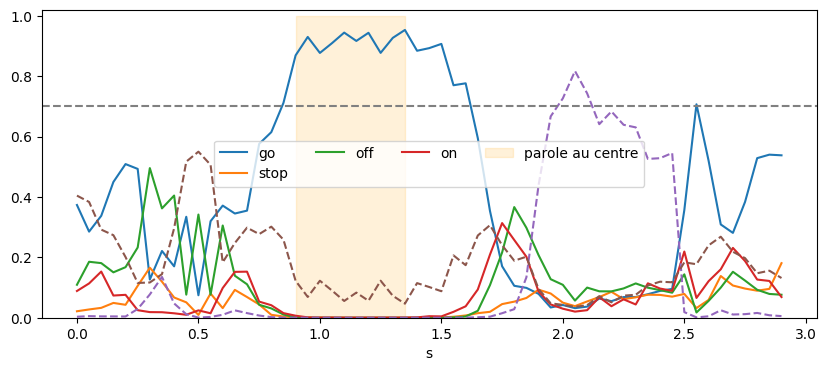

t = 1.35 s       go   p = 0.953


In [41]:
import matplotlib.pyplot as plt
from IPython.display import display, Javascript, Audio
from google.colab.output import eval_js
from base64 import b64decode
import subprocess



# 1) enregistrement micro -> WAV 16 kHz mono
def record(sec=4.0, out="rec.wav"):
    display(Javascript('''
    async function rec(ms){
      const s = await navigator.mediaDevices.getUserMedia({audio:true});
      const r = new MediaRecorder(s), ch = [];
      r.ondataavailable = e => ch.push(e.data);
      const done = new Promise(res => r.onstop = res);
      r.start(); await new Promise(t => setTimeout(t, ms)); r.stop(); await done;
      s.getTracks().forEach(t => t.stop());
      const b = new Blob(ch);
      return await new Promise(res => {const f = new FileReader();
        f.onloadend = () => res(f.result); f.readAsDataURL(b);});
    }'''))
    data = eval_js(f"rec({int(sec*1000)})")
    open("rec.webm", "wb").write(b64decode(data.split(",")[1]))
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", "rec.webm",
                    "-ar", "16000", "-ac", "1", out], check=True)
    return out

def detect(path, thr=0.7, hop=0.05, min_win=3, gate=0.25, show=True):
    sr, x = wavfile.read(path); assert sr == SR, sr
    x = x.astype(np.float32) / 32768.0
    xp = np.pad(x, (N // 2, N // 2))                       # t = centre de la fenêtre
    starts = np.arange(0, len(xp) - N + 1, int(hop * SR))
    W = np.stack([xp[a:a + N] for a in starts])
    P = tf.nn.softmax(model(spectro(W), training=False)).numpy()
    t = starts / SR

    # parole présente au centre de la fenêtre (0.3 s centrales)
    rms = np.sqrt((W[:, N//2 - 2400: N//2 + 2400] ** 2).mean(1))
    ok = rms > gate * rms.max()

    hits = []
    for k, c in enumerate(CLASSES):
        if c.startswith("_"): continue
        idx = np.where((P[:, k] > thr) & ok)[0]
        if len(idx) == 0: continue
        for g in np.split(idx, np.where(np.diff(idx) > 1)[0] + 1):
            if len(g) >= min_win:                         # au moins min_win fenêtres de suite
                j = g[np.argmax(P[g, k])]
                hits.append((t[j], c, P[j, k]))

    if show:
        plt.figure(figsize=(10, 4))
        for k, c in enumerate(CLASSES):
            plt.plot(t, P[:, k], label=c, ls="--" if c.startswith("_") else "-")
        plt.fill_between(t, 0, 1, where=ok, color="orange", alpha=0.15, label="parole au centre")
        plt.axhline(thr, ls="--", c="gray")
        plt.ylim(0, 1.02); plt.xlabel("s"); plt.legend(ncol=4); plt.show()

    if not hits: print("aucun mot détecté")
    for tt, c, p in sorted(hits):
        print(f"t = {tt:.2f} s   {c:>6s}   p = {p:.3f}")

path = record(3.0)
display(Audio(path))
detect(path, thr=0.7)

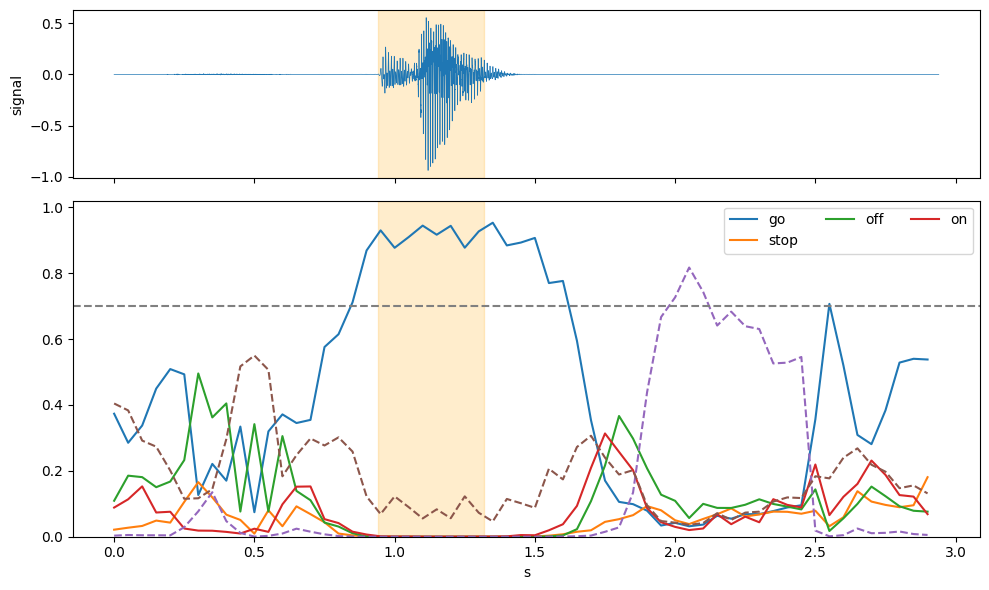

In [42]:
import matplotlib.pyplot as plt

def plot_probs(path, thr=0.7, hop=0.05):
    sr, x = wavfile.read(path); assert sr == SR, sr
    x = x.astype(np.float32) / 32768.0
    xp = np.pad(x, (N // 2, N // 2))                 # t = centre de la fenêtre
    starts = np.arange(0, len(xp) - N + 1, int(hop * SR))
    W = np.stack([xp[a:a + N] for a in starts])
    P = tf.nn.softmax(model(spectro(W), training=False)).numpy()
    t = starts / SR

    fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                           gridspec_kw={"height_ratios": [1, 2]})
    ax[0].plot(np.arange(len(x)) / SR, x, lw=0.5)
    ax[0].set_ylabel("signal")
    for a, b in segments(x):
        for axx in ax: axx.axvspan(a / SR, b / SR, color="orange", alpha=0.2)
    for k, c in enumerate(CLASSES):
        ax[1].plot(t, P[:, k], label=c, ls="--" if c.startswith("_") else "-")
    ax[1].axhline(thr, ls="--", c="gray")
    ax[1].set_ylim(0, 1.02); ax[1].set_xlabel("s"); ax[1].legend(ncol=3)
    plt.tight_layout(); plt.show()

plot_probs(path, thr=0.7)